# Step 09 — Explainable AI with SHAP

This notebook explains the predictions generated by the selected Competence → Employability model.

The selected predictors are:

- Life & Career Skills
- Learning & Innovation Skills
- Information Technology & Media Skills

The target variable is overall Employability (`EVS_avg`).

SHAP is used to evaluate both global feature importance and individual prediction contributions. The explanations describe how the trained model uses the selected competence features and should not be interpreted as causal effects.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import shap

d:\internship-employability-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase2_competence_prepared.csv"
)

RESULT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase2"
    / "shap_explainability"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project directory:", PROJECT_DIR)
print("Dataset:", DATA_PATH)
print("Results directory:", RESULT_DIR)

Project directory: d:\internship-employability-project
Dataset: d:\internship-employability-project\data\processed\phase2_competence_prepared.csv
Results directory: d:\internship-employability-project\reports\phase2\shap_explainability


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


In [4]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


In [5]:
FEATURES = [
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]

TARGET = "EVS_avg"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(TARGET)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['LifeCareer_avg', 'LearningInnovation_avg', 'ITMedia_avg']

Target:
EVS_avg

X shape: (1000, 3)
y shape: (1000,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [7]:
final_candidate_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

final_candidate_model.fit(
    X_train,
    y_train
)

test_predictions = final_candidate_model.predict(
    X_test
)

print("Candidate model trained successfully.")

Candidate model trained successfully.


Verify Model Performance

In [8]:
test_r2 = r2_score(
    y_test,
    test_predictions
)

test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_predictions
    )
)

print("Test R²:", test_r2)
print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)

Test R²: 0.5457322654308476
Test MAE: 0.18239694217253344
Test RMSE: 0.2572900418206848


Extract Scaler and Linear Model

In [9]:
scaler = final_candidate_model.named_steps["scaler"]
linear_model = final_candidate_model.named_steps["model"]

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=FEATURES,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=FEATURES,
    index=X_test.index
)

X_test_scaled.head()

,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg
521,0.39564,0.081164,0.224635
737,0.39564,0.081164,0.224635
740,0.39564,0.081164,0.224635
660,0.39564,0.081164,0.224635
411,0.39564,0.081164,0.224635


Create SHAP Explainer

In [10]:
explainer = shap.LinearExplainer(
    linear_model,
    X_train_scaled
)

shap_values = explainer(
    X_test_scaled
)

print("SHAP values shape:", shap_values.values.shape)

Background dataset has 800 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=800 when initializing the masker.


SHAP values shape: (200, 3)


Global SHAP Importance Table

තියෙන feature එක model එකේ overall prediction වලට වැඩි influence එකක් තියෙනවා.

In [11]:
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

global_shap_importance = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Absolute_SHAP": mean_abs_shap
})

global_shap_importance = (
    global_shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

global_shap_importance

,Feature,Mean_Absolute_SHAP
0,ITMedia_avg,0.080921
1,LifeCareer_avg,0.067069
2,LearningInnovation_avg,0.049958


Global Feature Importance Bar Plot

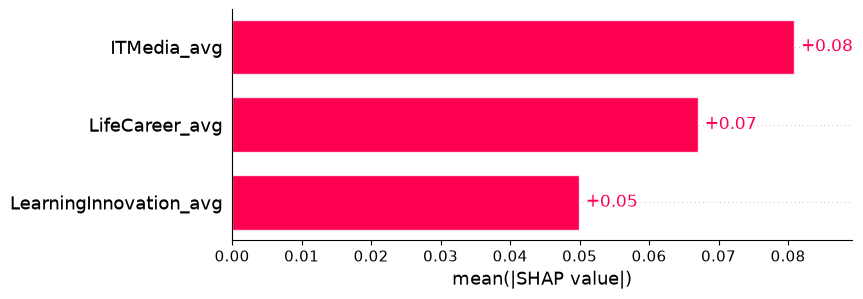

In [12]:
shap.plots.bar(
    shap_values,
    max_display=3
)

SHAP Beeswarm Plot

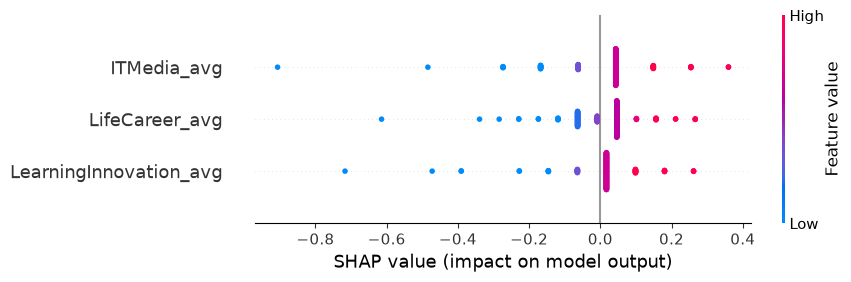

In [13]:
shap.plots.beeswarm(
    shap_values,
    max_display=3
)

Linear Regression Coefficients

In [14]:
coefficient_table = pd.DataFrame({
    "Feature": FEATURES,
    "Standardized_Coefficient": linear_model.coef_
})

coefficient_table["Absolute_Coefficient"] = (
    coefficient_table[
        "Standardized_Coefficient"
    ].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

coefficient_table

,Feature,Standardized_Coefficient,Absolute_Coefficient
0,ITMedia_avg,0.121541,0.121541
1,LifeCareer_avg,0.087668,0.087668
2,LearningInnovation_avg,0.082907,0.082907


Combine SHAP Importance and Coefficients

In [15]:
explanation_summary = global_shap_importance.merge(
    coefficient_table[
        [
            "Feature",
            "Standardized_Coefficient"
        ]
    ],
    on="Feature",
    how="left"
)

explanation_summary["Direction"] = np.where(
    explanation_summary[
        "Standardized_Coefficient"
    ] >= 0,
    "Positive",
    "Negative"
)

explanation_summary

,Feature,Mean_Absolute_SHAP,Standardized_Coefficient,Direction
0,ITMedia_avg,0.080921,0.121541,Positive
1,LifeCareer_avg,0.067069,0.087668,Positive
2,LearningInnovation_avg,0.049958,0.082907,Positive


Individual Prediction Example

In [17]:
sample_position = 0

sample_index = X_test.index[
    sample_position
]

sample_raw = X_test.loc[
    sample_index
]

sample_actual = y_test.loc[
    sample_index
]

sample_prediction = test_predictions[
    sample_position
]

print("Sample index:", sample_index)

print("\nInput Features:")
print(sample_raw)

print("\nActual EVS_avg:")
print(sample_actual)

print("\nPredicted EVS_avg:")
print(sample_prediction)

Sample index: 521

Input Features:
LifeCareer_avg            4.0
LearningInnovation_avg    4.0
ITMedia_avg               4.0
Name: 521, dtype: float64

Actual EVS_avg:
4.333333333333333

Predicted EVS_avg:
4.1674665355499325


Individual SHAP Waterfall Plot

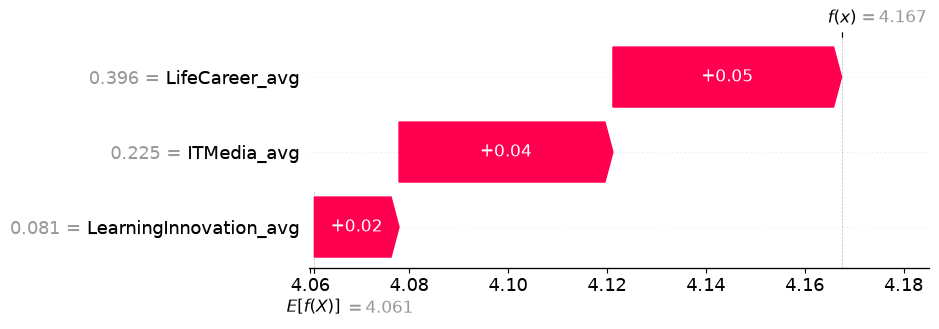

In [18]:
shap.plots.waterfall(
    shap_values[
        sample_position
    ],
    max_display=3
)

Individual SHAP Contribution Table

In [19]:
individual_explanation = pd.DataFrame({
    "Feature": FEATURES,
    "Feature_Value": sample_raw.values,
    "SHAP_Value": shap_values[
        sample_position
    ].values
})

individual_explanation["Effect"] = np.where(
    individual_explanation[
        "SHAP_Value"
    ] >= 0,
    "Increases Prediction",
    "Decreases Prediction"
)

individual_explanation = individual_explanation.sort_values(
    "SHAP_Value",
    key=lambda x: x.abs(),
    ascending=False
).reset_index(drop=True)

individual_explanation

,Feature,Feature_Value,SHAP_Value,Effect
0,LifeCareer_avg,4.0,0.046247,Increases Prediction
1,ITMedia_avg,4.0,0.043262,Increases Prediction
2,LearningInnovation_avg,4.0,0.017129,Increases Prediction


Verify SHAP Prediction Decomposition

In [20]:
base_value = float(
    np.array(
        shap_values.base_values[
            sample_position
        ]
    ).reshape(-1)[0]
)

shap_contribution = shap_values[
    sample_position
].values.sum()

reconstructed_prediction = (
    base_value
    +
    shap_contribution
)

print("Base value:", base_value)
print("Total SHAP contribution:", shap_contribution)

print(
    "Reconstructed prediction:",
    reconstructed_prediction
)

print(
    "Model prediction:",
    sample_prediction
)

print(
    "Difference:",
    abs(
        reconstructed_prediction
        -
        sample_prediction
    )
)

Base value: 4.060829493462149
Total SHAP contribution: 0.1066370420877828
Reconstructed prediction: 4.1674665355499325
Model prediction: 4.1674665355499325
Difference: 0.0


Create SHAP Values Dataset

In [21]:
shap_values_df = pd.DataFrame(
    shap_values.values,
    columns=[
        f"SHAP_{feature}"
        for feature in FEATURES
    ],
    index=X_test.index
)

shap_values_df["Actual_EVS_avg"] = (
    y_test
)

shap_values_df["Predicted_EVS_avg"] = (
    test_predictions
)

shap_values_df.head()

,SHAP_LifeCareer_avg,SHAP_LearningInnovation_avg,SHAP_ITMedia_avg,Actual_EVS_avg,Predicted_EVS_avg
521,0.046247,0.017129,0.043262,4.333333,4.167467
737,0.046247,0.017129,0.043262,4.333333,4.167467
740,0.046247,0.017129,0.043262,4.000000,4.167467
660,0.046247,0.017129,0.043262,4.250000,4.167467
411,0.046247,0.017129,0.043262,4.333333,4.167467


In [22]:
global_shap_importance.to_csv(
    RESULT_DIR
    / "Global_SHAP_Feature_Importance.csv",
    index=False
)

coefficient_table.to_csv(
    RESULT_DIR
    / "Linear_Regression_Coefficients.csv",
    index=False
)

explanation_summary.to_csv(
    RESULT_DIR
    / "SHAP_Explanation_Summary.csv",
    index=False
)

individual_explanation.to_csv(
    RESULT_DIR
    / "Individual_SHAP_Explanation.csv",
    index=False
)

shap_values_df.to_csv(
    RESULT_DIR
    / "Test_Set_SHAP_Values.csv",
    index=True
)

print("All SHAP results saved successfully.")

All SHAP results saved successfully.


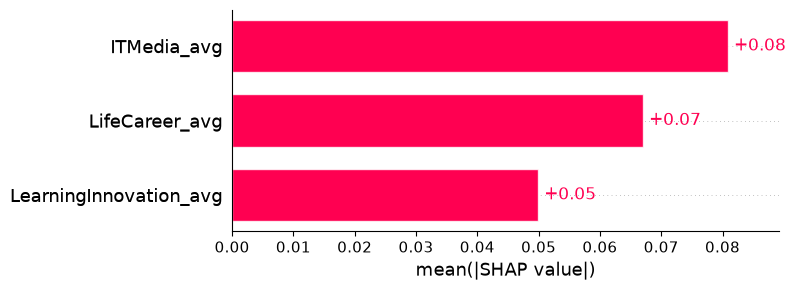

In [23]:
shap.plots.bar(
    shap_values,
    max_display=3,
    show=False
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR
    / "SHAP_Global_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

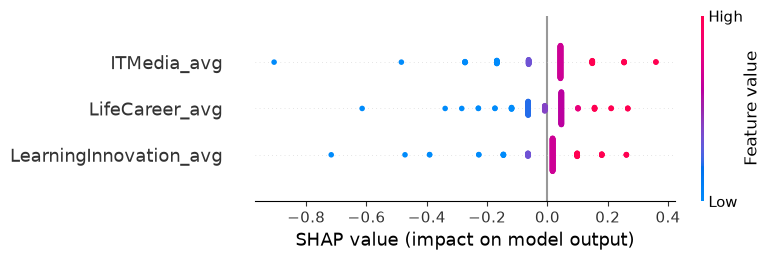

In [24]:
shap.plots.beeswarm(
    shap_values,
    max_display=3,
    show=False
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR
    / "SHAP_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 09 Conclusion

SHAP analysis was used to explain the predictions generated by the selected Linear Regression model.

Global SHAP importance identified the relative contribution of the three competence constructs to Employability prediction. The direction of each relationship was also examined using standardized Linear Regression coefficients.

Individual SHAP explanations demonstrated how each competence construct contributed to a specific Employability prediction.

These explanations improve model transparency and provide an evidence base for the recommendation system developed in the next stage. SHAP values represent the behaviour of the trained prediction model and are not interpreted as causal effects.

## Step 09 Conclusion

SHAP analysis was successfully applied to the selected Linear Regression model to improve prediction transparency.

Global SHAP analysis identified IT & Media Skills as the most influential competence construct in the model, followed by Life & Career Skills and Learning & Innovation Skills.

The standardized Linear Regression coefficients were positive for all three competence constructs, indicating that higher competence levels were associated with higher predicted Employability scores within the fitted model.

Individual SHAP analysis demonstrated how each competence construct contributed to a specific Employability prediction. The SHAP decomposition exactly reconstructed the model prediction, with a difference of 0.0 between the reconstructed and original prediction.

These results confirm that the selected model can provide transparent and interpretable predictions and provide an evidence base for the recommendation system developed in the next stage.

What did SHAP show?"

කියලා නම්:

"SHAP showed that IT and Media Skills had the highest overall influence on employability predictions, followed by Life and Career Skills and Learning and Innovation Skills. All three factors had positive model coefficients. I also validated an individual prediction, where the SHAP contributions exactly reconstructed the model prediction."

SHAP dependence plots

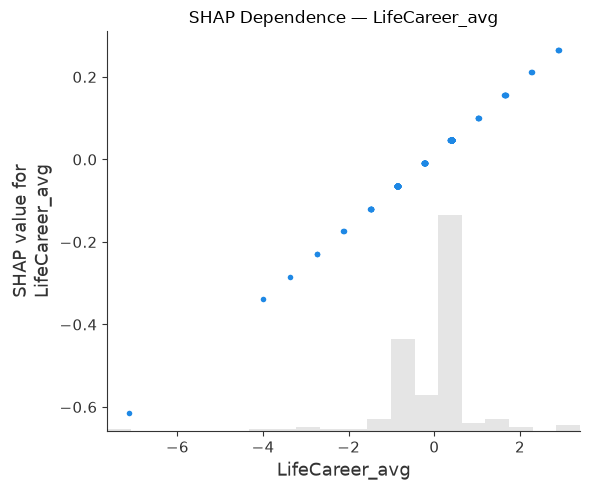

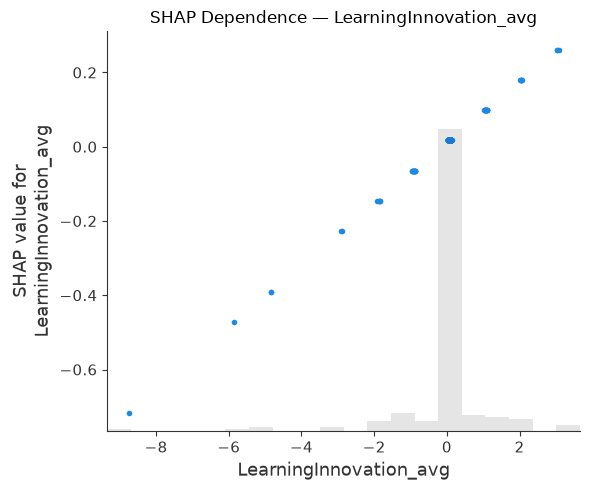

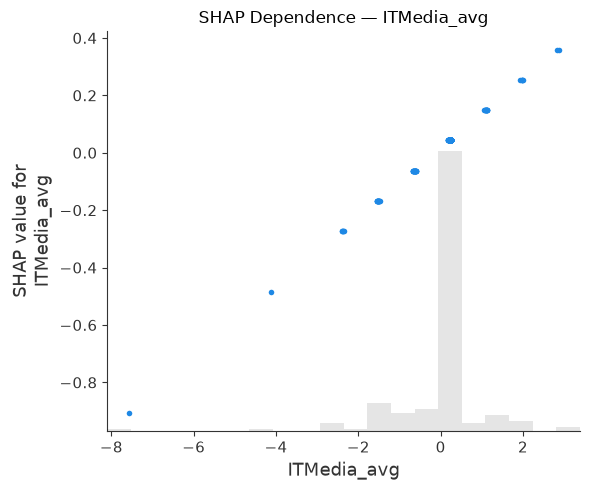

In [25]:
for feature in FEATURES:
    shap.plots.scatter(
        shap_values[:, feature],
        show=False
    )

    plt.title(
        f"SHAP Dependence — {feature}"
    )

    plt.tight_layout()
    plt.show()

Low-score individual explanation එකක්

In [26]:
low_position = np.argmin(test_predictions)

low_index = X_test.index[low_position]

print("Low-score sample:")
print(X_test.loc[low_index])

print("\nActual EVS_avg:")
print(y_test.loc[low_index])

print("\nPredicted EVS_avg:")
print(test_predictions[low_position])

Low-score sample:
LifeCareer_avg            1.0
LearningInnovation_avg    1.0
ITMedia_avg               1.0
Name: 213, dtype: float64

Actual EVS_avg:
1.0

Predicted EVS_avg:
1.8230715010649359


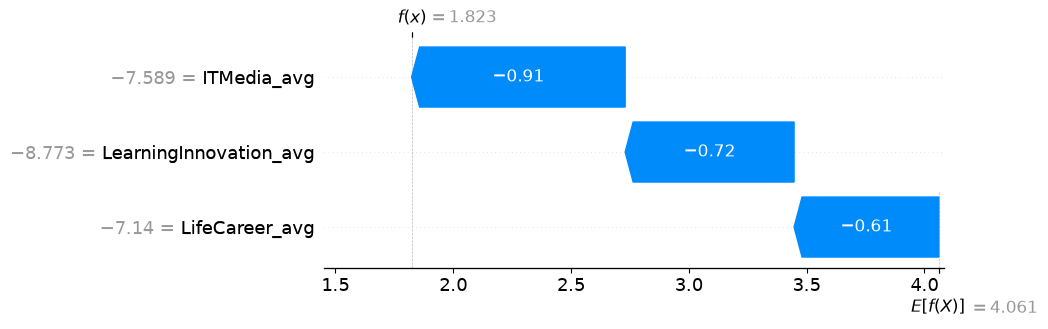

In [27]:
shap.plots.waterfall(
    shap_values[low_position],
    max_display=3
)